### Image Denoising Using a Time-Fractional Diffusion Equation

We model denoising using

$$
{}^{C}D_t^\alpha u=c_d\Delta u,
\qquad u(x,y,0)=u_0(x,y).
$$

Diffusion reduces noise but can blur edges, making the stopping time important. The fractional order $\alpha$ controls the smoothing, with $\alpha=1$ giving the standard heat equation.

Unlike binarization, no reaction term is used because grey levels must be preserved. We use finite differences, Neumann boundary conditions, the L1 scheme, and Crank–Nicolson time-stepping.

In [118]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from math import gamma
from scipy.fft import dctn, idctn
from skimage import data
from matplotlib.colors import Normalize, LightSource, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

In [119]:
import os
import matplotlib.pyplot as plt

os.makedirs("crankplots", exist_ok=True)

_original_show = plt.show
_plot_count = 0

def show_and_save(*args, **kwargs):
    global _plot_count
    for num in plt.get_fignums():
        _plot_count += 1
        fig = plt.figure(num)
        fig.savefig(
            f"crankplots/plot_{_plot_count:02d}.png",
            dpi=200, bbox_inches="tight", facecolor="white"
        )
    _original_show(*args, **kwargs)

plt.show = show_and_save

### Normalization and the Laplacian

The `normalize` function scales the clean image to \([0,1]\), while the noisy image remains on the same intensity scale.

The `laplacian_neumann` function uses a 5-point stencil with edge padding to apply the Neumann boundary condition.

The `neumann_eigenvalues` function calculates the eigenvalues used to solve the Crank–Nicolson system efficiently.

In [120]:
def normalize(img):
    img = img.astype(float)
    return (img - img.min()) / (img.max() - img.min() + 1e-12)


def laplacian_neumann(u, h=1.0):
    u = np.pad(u, 1, mode="edge")
    return (u[:-2, 1:-1] + u[2:, 1:-1] +
            u[1:-1, :-2] + u[1:-1, 2:] -
            4*u[1:-1, 1:-1]) / h**2


def neumann_eigenvalues(shape, h=1.0):
    ny, nx = shape
    y = -4/h**2 * np.sin(np.pi*np.arange(ny)/(2*ny))**2
    x = -4/h**2 * np.sin(np.pi*np.arange(nx)/(2*nx))**2
    return y[:, None] + x[None, :]

###  L1 Time-Stepping with Crank–Nicolson Diffusion

The L1 approximation of the Caputo derivative is

$$
{}^{C}D_t^\alpha u(t_{n+1})
\approx c\sum_{k=0}^{n}b_k
\left(u^{n+1-k}-u^{n-k}\right)
$$

where

$$
b_k=(k+1)^{1-\alpha}-k^{1-\alpha},
\qquad
c=\frac{1}{\Gamma(2-\alpha)(\Delta t)^\alpha}.
$$

The memory term is

$$
\mathrm{mem}=\sum_{k=1}^{n}b_k
\left(u^{n+1-k}-u^{n-k}\right)
$$

Define

$$
\theta=\frac{c_d}{2c}.
$$

The time-stepping scheme is

$$
(I-\theta\Delta_h)u^{n+1}
=u^n+\theta\Delta_hu^n-\mathrm{mem}
$$

The eigenvalues of the discrete Neumann Laplacian are

$$
\lambda_{jk}=-\frac{4}{h^2}
\left[
\sin^2\left(\frac{\pi j}{2n_y}\right)
+\sin^2\left(\frac{\pi k}{2n_x}\right)
\right].
$$

In [121]:
def solve(u0, alpha, dt, n_steps, h=1.0, c_d=1.0, window=None):
    c = dt**(-alpha) / gamma(2 - alpha)
    k = np.arange(n_steps + 1)
    b = (k + 1)**(1 - alpha) - k**(1 - alpha)

    theta = c_d / (2 * c)
    denom = 1 - theta * neumann_eigenvalues(u0.shape, h)

    u = u0.copy()
    diffs = []
    traj = [u.copy()]

    for n in range(n_steps):
        hist = diffs if window is None else diffs[-window:]
        mem = np.zeros_like(u)

        for j in range(1, len(hist) + 1):
            mem += b[j] * hist[-j]

        rhs = u + theta * laplacian_neumann(u, h) - mem
        u_new = idctn(
            dctn(rhs, type=2, norm="ortho") / denom,
            type=2, norm="ortho"
        )

        diffs.append(u_new - u)
        u = u_new
        traj.append(u.copy())

    return traj


def solve_explicit(u0, alpha, dt, n_steps, h=1.0, c_d=1.0, window=None):
    c = dt**(-alpha) / gamma(2 - alpha)
    k = np.arange(n_steps + 1)
    b = (k + 1)**(1 - alpha) - k**(1 - alpha)

    u = u0.copy()
    diffs = []
    traj = [u.copy()]

    for n in range(n_steps):
        rhs = c_d * laplacian_neumann(u, h)
        hist = diffs if window is None else diffs[-window:]
        mem = np.zeros_like(u)

        for j in range(1, len(hist) + 1):
            mem += b[j] * hist[-j]

        u_new = u - mem + rhs / c
        diffs.append(u_new - u)
        u = u_new
        traj.append(u.copy())

    return traj

Saving TW_Kambule_Building.jpg to TW_Kambule_Building (3).jpg


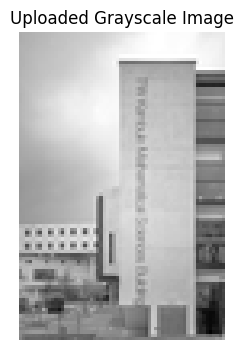

In [122]:
from google.colab import files
from PIL import Image, ImageOps
import io
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
name = next(iter(uploaded))
img = Image.open(io.BytesIO(uploaded[name]))
img = ImageOps.exif_transpose(img).convert("L")

max_side = 96
scale = min(1, max_side / max(img.size))
size = (round(img.width * scale), round(img.height * scale))
img = img.resize(size, Image.Resampling.LANCZOS)

clean_image = np.array(img, dtype=float) / 255

plt.figure(figsize=(8, 4))
plt.imshow(clean_image, cmap="gray", vmin=0, vmax=1)
plt.title("Uploaded Grayscale Image")
plt.axis("off")
plt.show()

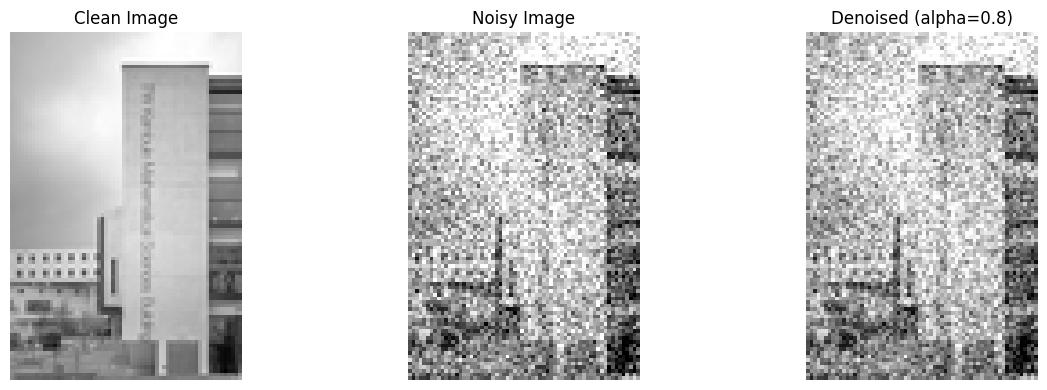

In [123]:
from scipy.special import gamma
from scipy.fft import dctn, idctn

sigma = 0.15
rng = np.random.default_rng(42)
noisy_image = np.clip(
    clean_image + rng.normal(0, sigma, clean_image.shape), 0, 1
)

alpha = 0.8
dt = 0.01
n_steps = 20
c_d = 0.1

trajectory = solve(
    noisy_image, alpha, dt, n_steps, c_d=c_d
)

denoised_image = trajectory[-1]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, image, title in zip(
    axes,
    [clean_image, noisy_image, denoised_image],
    ["Clean Image", "Noisy Image", f"Denoised (alpha={alpha})"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### The Error Metric

We measure denoising quality using the peak signal-to-noise ratio (PSNR):

\\[ \mathrm{PSNR}(u)=10\log\_{10}\left(\frac{1}{\mathrm{MSE}(u)}\right) \\]

\\[ \mathrm{MSE}(u)=\frac{1}{N}\sum\_{i=1}^{N}(u_i-u_i^{\mathrm{clean}})^2 \\]

Since pixel values lie in \\([0,1]\\), a higher PSNR (in dB) indicates better image quality. We compare grey levels directly without thresholding.

PSNR is calculated at every time step to track image quality and identify the best stopping time. The `run` function stores the PSNR curve, best image and final image.

In [124]:
def psnr(u, gt):
    mse = np.mean((u - gt)**2)
    return 10 * np.log10(1 / mse)


def run(u0, gt, alpha, dt, n_steps, **kw):
    traj = solve(u0, alpha, dt, n_steps, **kw)
    scores = [psnr(u, gt) for u in traj]
    best = np.argmax(scores)

    return {
        "psnr": scores,
        "best_step": best,
        "best_img": traj[best],
        "final_img": traj[-1]
    }

Noisy input PSNR: 20.04 dB


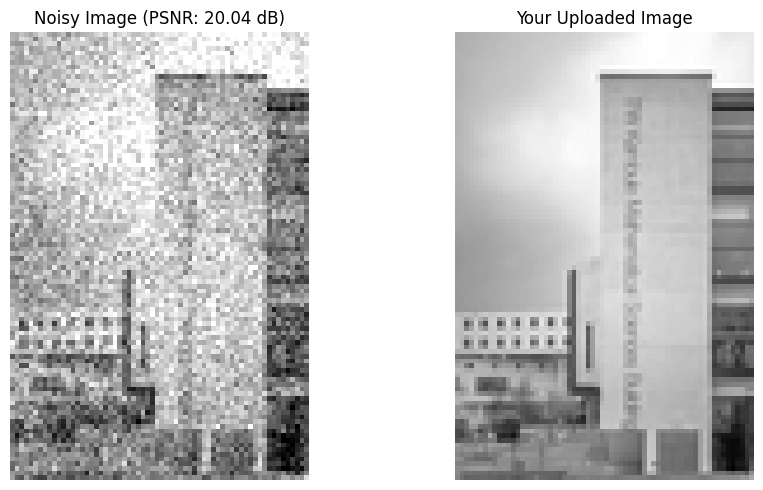

In [125]:
rng = np.random.default_rng(0)

gt = normalize(clean_image)
noisy = gt + 0.1 * rng.standard_normal(gt.shape)
u0 = noisy

print(f"Noisy input PSNR: {psnr(u0, gt):.2f} dB")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(np.clip(u0, 0, 1), cmap="gray", vmin=0, vmax=1)
ax[0].set_title(f"Noisy Image (PSNR: {psnr(u0, gt):.2f} dB)")

ax[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Your Uploaded Image")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

Comparing Crank–Nicolson with the Explicit Scheme
Both schemes give similar results for small time steps. For larger time steps, the explicit scheme becomes unstable, while Crank–Nicolson remains bounded.

In [126]:
for dt in [0.01, 0.5, 2.0]:
    for alpha in [1, 0.5]:
        with np.errstate(all="ignore"):
            te = solve_explicit(u0, alpha, dt, 40)

        tc = solve(u0, alpha, dt, 40)

        print(
            f"dt={dt}, alpha={alpha} | "
            f"Explicit: {np.abs(te[-1]).max():.3g} | "
            f"Crank-Nicolson: {np.abs(tc[-1]).max():.3g}"
        )

dt=0.01, alpha=1 | Explicit: 1.1 | Crank-Nicolson: 1.11
dt=0.01, alpha=0.5 | Explicit: 1.09 | Crank-Nicolson: 1.09
dt=0.5, alpha=1 | Explicit: 3.14e+17 | Crank-Nicolson: 0.93
dt=0.5, alpha=0.5 | Explicit: 2.16e+24 | Crank-Nicolson: 1.01
dt=2.0, alpha=1 | Explicit: 3.2e+45 | Crank-Nicolson: 0.835
dt=2.0, alpha=0.5 | Explicit: 2.89e+37 | Crank-Nicolson: 0.981


Sweep \\(\alpha\\). For each fractional order, we record the PSNR at every step and identify the best PSNR, its stopping time, and the final PSNR to measure quality loss.

In [127]:
alphas = [1, 0.8, 0.75, 0.6, 0.5, 0.25]
DT = 0.01
N_STEPS = 300

results = {}

for a in alphas:
    results[a] = run(u0, gt, a, DT, N_STEPS)
    scores = results[a]["psnr"]
    best = results[a]["best_step"]

    print(f"Alpha: {a}")
    print(f"Best PSNR: {scores[best]:.2f} dB")
    print(f"Best step: {best} (t = {best * DT:.2f})")
    print(f"Final PSNR: {scores[-1]:.2f} dB")

Alpha: 1
Best PSNR: 25.57 dB
Best step: 37 (t = 0.37)
Final PSNR: 22.16 dB
Alpha: 0.8
Best PSNR: 25.50 dB
Best step: 32 (t = 0.32)
Final PSNR: 22.85 dB
Alpha: 0.75
Best PSNR: 25.48 dB
Best step: 30 (t = 0.30)
Final PSNR: 23.02 dB
Alpha: 0.6
Best PSNR: 25.42 dB
Best step: 26 (t = 0.26)
Final PSNR: 23.52 dB
Alpha: 0.5
Best PSNR: 25.39 dB
Best step: 22 (t = 0.22)
Final PSNR: 23.84 dB
Alpha: 0.25
Best PSNR: 25.59 dB
Best step: 1 (t = 0.01)
Final PSNR: 24.55 dB


## PSNR curves.
A curve that rises and then falls means the image is first denoised and then over-smoothed, so stopping early matters. The dotted line is the PSNR of the noisy input.

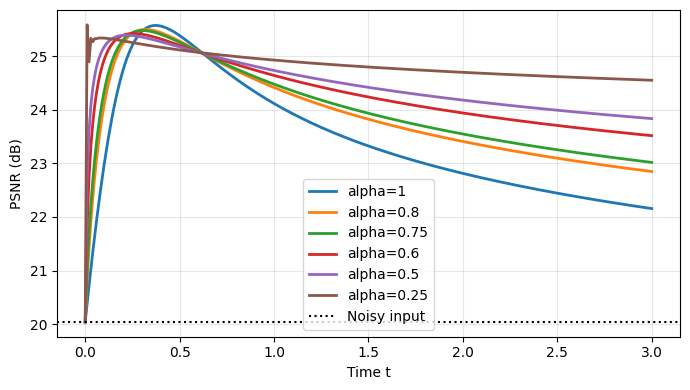

In [128]:
plt.figure(figsize=(7, 4))

for a, res in results.items():
    t = np.arange(len(res["psnr"])) * DT
    plt.plot(t, res["psnr"], linewidth=2, label=f"alpha={a}")

plt.axhline(psnr(u0, gt), color="black", linestyle=":", label="Noisy input")
plt.xlabel("Time t")
plt.ylabel("PSNR (dB)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

For each $\alpha$ we show the denoised image at its best stopping step and at the final step, so you can see the quality difference.

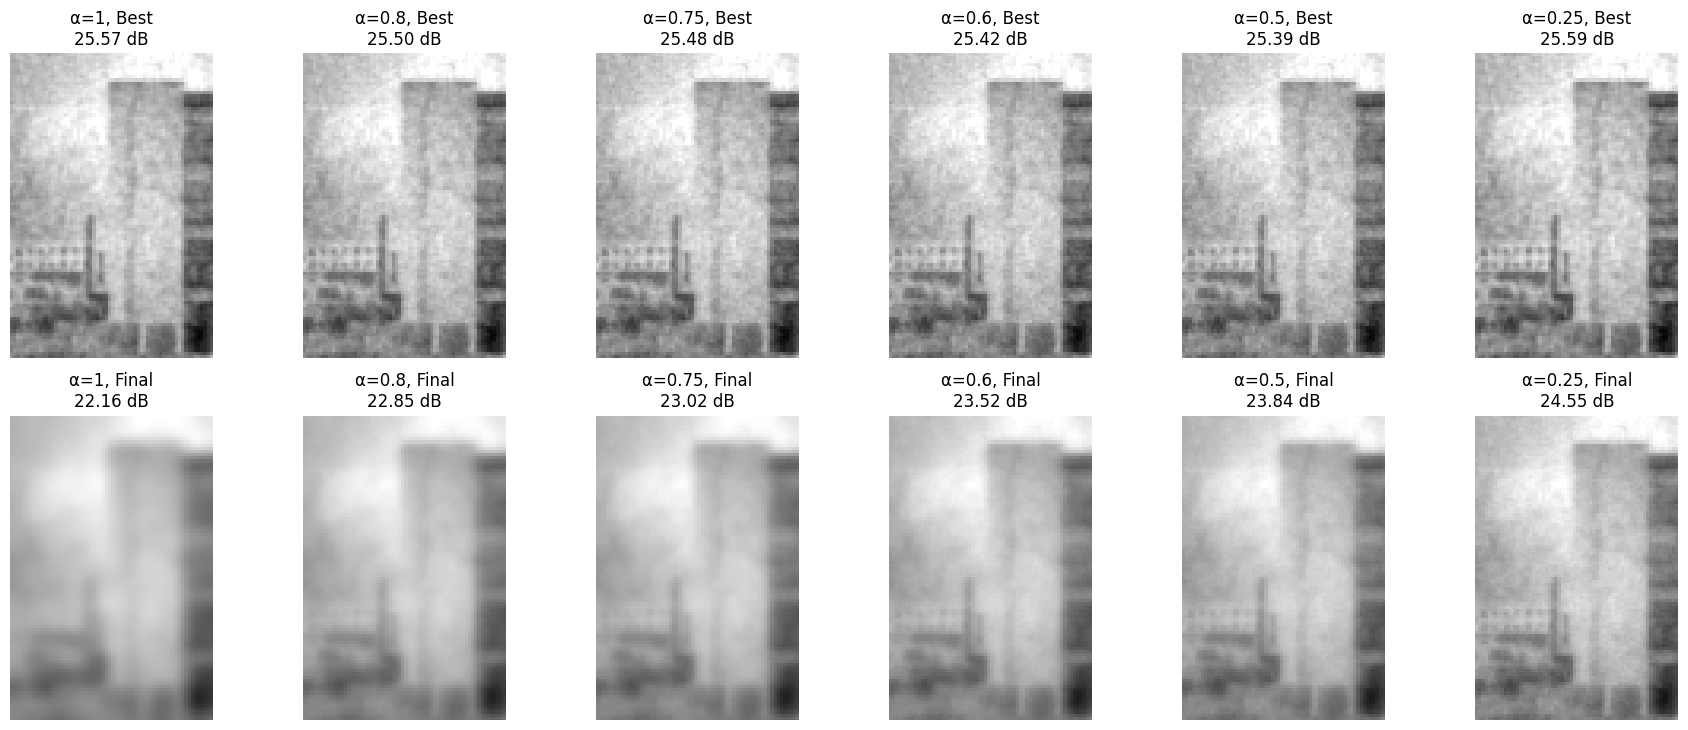

In [129]:
fig, axes = plt.subplots(2, len(alphas), figsize=(3 * len(alphas), 7.4))

for j, a in enumerate(alphas):
    res = results[a]
    best = res["best_step"]

    axes[0, j].imshow(res["best_img"], cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"α={a}, Best\n{res['psnr'][best]:.2f} dB")

    axes[1, j].imshow(res["final_img"], cmap="gray", vmin=0, vmax=1)
    axes[1, j].set_title(f"α={a}, Final\n{res['psnr'][-1]:.2f} dB")

    axes[0, j].axis("off")
    axes[1, j].axis("off")

plt.tight_layout()
plt.show()

## Comparing noise levels $\sigma = 0.05$, $\sigma = 0.1$ and $\sigma = 0.2$ Using PSNR Measurements and Plots

This replaces the comparison of reaction coefficients $c_s$ from the binarization version. Here we ask how the behaviour changes when the input is more or less noisy.

In [130]:
sigmas = [0.05, 0.1, 0.2]
comparison = {}

for sigma in sigmas:
    noisy = gt + sigma * np.random.default_rng(0).standard_normal(gt.shape)
    data = {"noisy": noisy, "noisy_psnr": psnr(noisy, gt)}

    for alpha in alphas:
        res = run(noisy, gt, alpha, DT, N_STEPS)
        data[alpha] = res
        best = res["best_step"]

        print(
            f"σ={sigma}, α={alpha}, "
            f"Noisy={data['noisy_psnr']:.2f} dB, "
            f"Best={res['psnr'][best]:.2f} dB (t={best * DT:.2f}), "
            f"Final={res['psnr'][-1]:.2f} dB"
        )

    comparison[sigma] = data

σ=0.05, α=1, Noisy=26.06 dB, Best=28.95 dB (t=0.17), Final=22.25 dB
σ=0.05, α=0.8, Noisy=26.06 dB, Best=28.90 dB (t=0.11), Final=22.99 dB
σ=0.05, α=0.75, Noisy=26.06 dB, Best=28.88 dB (t=0.09), Final=23.18 dB
σ=0.05, α=0.6, Noisy=26.06 dB, Best=28.85 dB (t=0.05), Final=23.76 dB
σ=0.05, α=0.5, Noisy=26.06 dB, Best=28.84 dB (t=0.03), Final=24.15 dB
σ=0.05, α=0.25, Noisy=26.06 dB, Best=28.19 dB (t=0.01), Final=25.16 dB
σ=0.1, α=1, Noisy=20.04 dB, Best=25.57 dB (t=0.37), Final=22.16 dB
σ=0.1, α=0.8, Noisy=20.04 dB, Best=25.50 dB (t=0.32), Final=22.85 dB
σ=0.1, α=0.75, Noisy=20.04 dB, Best=25.48 dB (t=0.30), Final=23.02 dB
σ=0.1, α=0.6, Noisy=20.04 dB, Best=25.42 dB (t=0.26), Final=23.52 dB
σ=0.1, α=0.5, Noisy=20.04 dB, Best=25.39 dB (t=0.22), Final=23.84 dB
σ=0.1, α=0.25, Noisy=20.04 dB, Best=25.59 dB (t=0.01), Final=24.55 dB
σ=0.2, α=1, Noisy=14.02 dB, Best=22.77 dB (t=0.86), Final=21.79 dB
σ=0.2, α=0.8, Noisy=14.02 dB, Best=22.81 dB (t=1.06), Final=22.30 dB
σ=0.2, α=0.75, Noisy=14.02 dB,

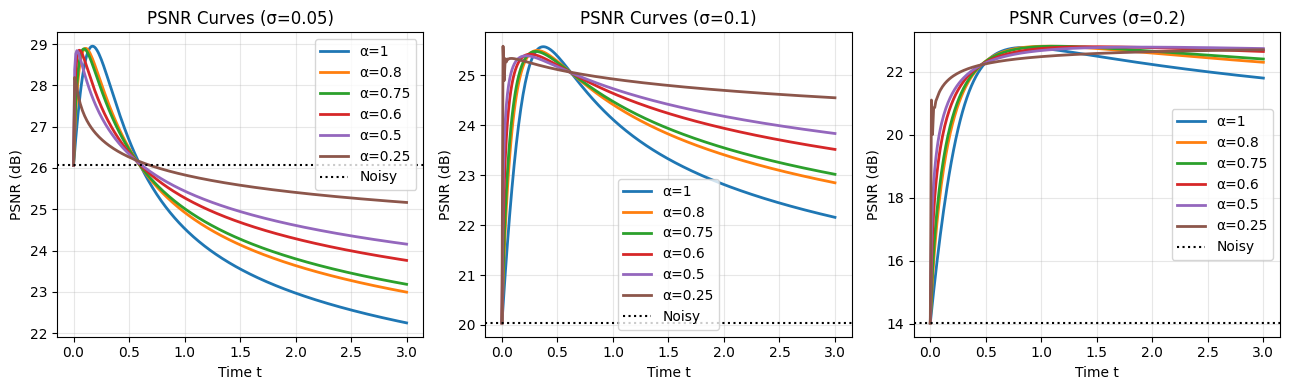

In [131]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, sigma in zip(axes, sigmas):
    for alpha in alphas:
        scores = comparison[sigma][alpha]["psnr"]
        t = np.arange(len(scores)) * DT
        ax.plot(t, scores, linewidth=2, label=f"α={alpha}")

    ax.axhline(
        comparison[sigma]["noisy_psnr"],
        color="black", linestyle=":", label="Noisy"
    )
    ax.set_title(f"PSNR Curves (σ={sigma})")
    ax.set_xlabel("Time t")
    ax.set_ylabel("PSNR (dB)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

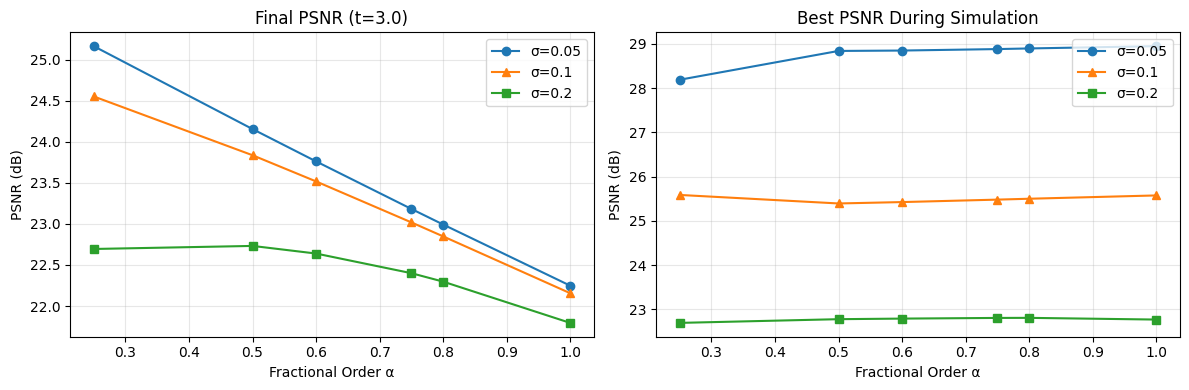

In [132]:
alphas_arr = np.array(alphas)
order = np.argsort(alphas_arr)


def best_final(sigma):
    scores = [comparison[sigma][a]["psnr"] for a in alphas]
    return np.array([max(s) for s in scores]), np.array([s[-1] for s in scores])


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for sigma, marker in zip(sigmas, ["o-", "^-", "s-"]):
    best_s, final_s = best_final(sigma)
    axes[0].plot(alphas_arr[order], final_s[order], marker, label=f"σ={sigma}")
    axes[1].plot(alphas_arr[order], best_s[order], marker, label=f"σ={sigma}")

axes[0].set_title(f"Final PSNR (t={N_STEPS * DT:.1f})")
axes[1].set_title("Best PSNR During Simulation")

for ax in axes:
    ax.set_xlabel("Fractional Order α")
    ax.set_ylabel("PSNR (dB)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Analysing how much the PSNR changes

In [133]:
rows = []

for sigma in sigmas:
    best_s, final_s = best_final(sigma)

    for a, best, final in zip(alphas, best_s, final_s):
        noisy_psnr = comparison[sigma]["noisy_psnr"]

        rows.append({
            "Sigma": sigma,
            "Alpha": a,
            "Noisy PSNR": noisy_psnr,
            "Best PSNR": best,
            "Best Time": comparison[sigma][a]["best_step"] * DT,
            "Final PSNR": final,
            "Best Gain (dB)": best - noisy_psnr,
            "Final Loss (dB)": best - final
        })

analysis = pd.DataFrame(rows)
display(analysis.round(2))

,Sigma,Alpha,Noisy PSNR,Best PSNR,Best Time,Final PSNR,Best Gain (dB),Final Loss (dB)
0,0.05,1.00,26.06,28.95,0.17,22.25,2.89,6.70
1,0.05,0.80,26.06,28.90,0.11,22.99,2.83,5.90
2,0.05,0.75,26.06,28.88,0.09,23.18,2.82,5.70
3,0.05,0.60,26.06,28.85,0.05,23.76,2.79,5.09
4,0.05,0.50,26.06,28.84,0.03,24.15,2.78,4.69
5,0.05,0.25,26.06,28.19,0.01,25.16,2.13,3.03
6,0.10,1.00,20.04,25.57,0.37,22.16,5.53,3.42
7,0.10,0.80,20.04,25.50,0.32,22.85,5.46,2.65
8,0.10,0.75,20.04,25.48,0.30,23.02,5.44,2.46
9,0.10,0.60,20.04,25.42,0.26,23.52,5.38,1.91


# Presentation plot for reference during the presentation

The surface plots show a zoomed-in patch of the denoised image (height = grey level) at each $\alpha$'s best stopping time.

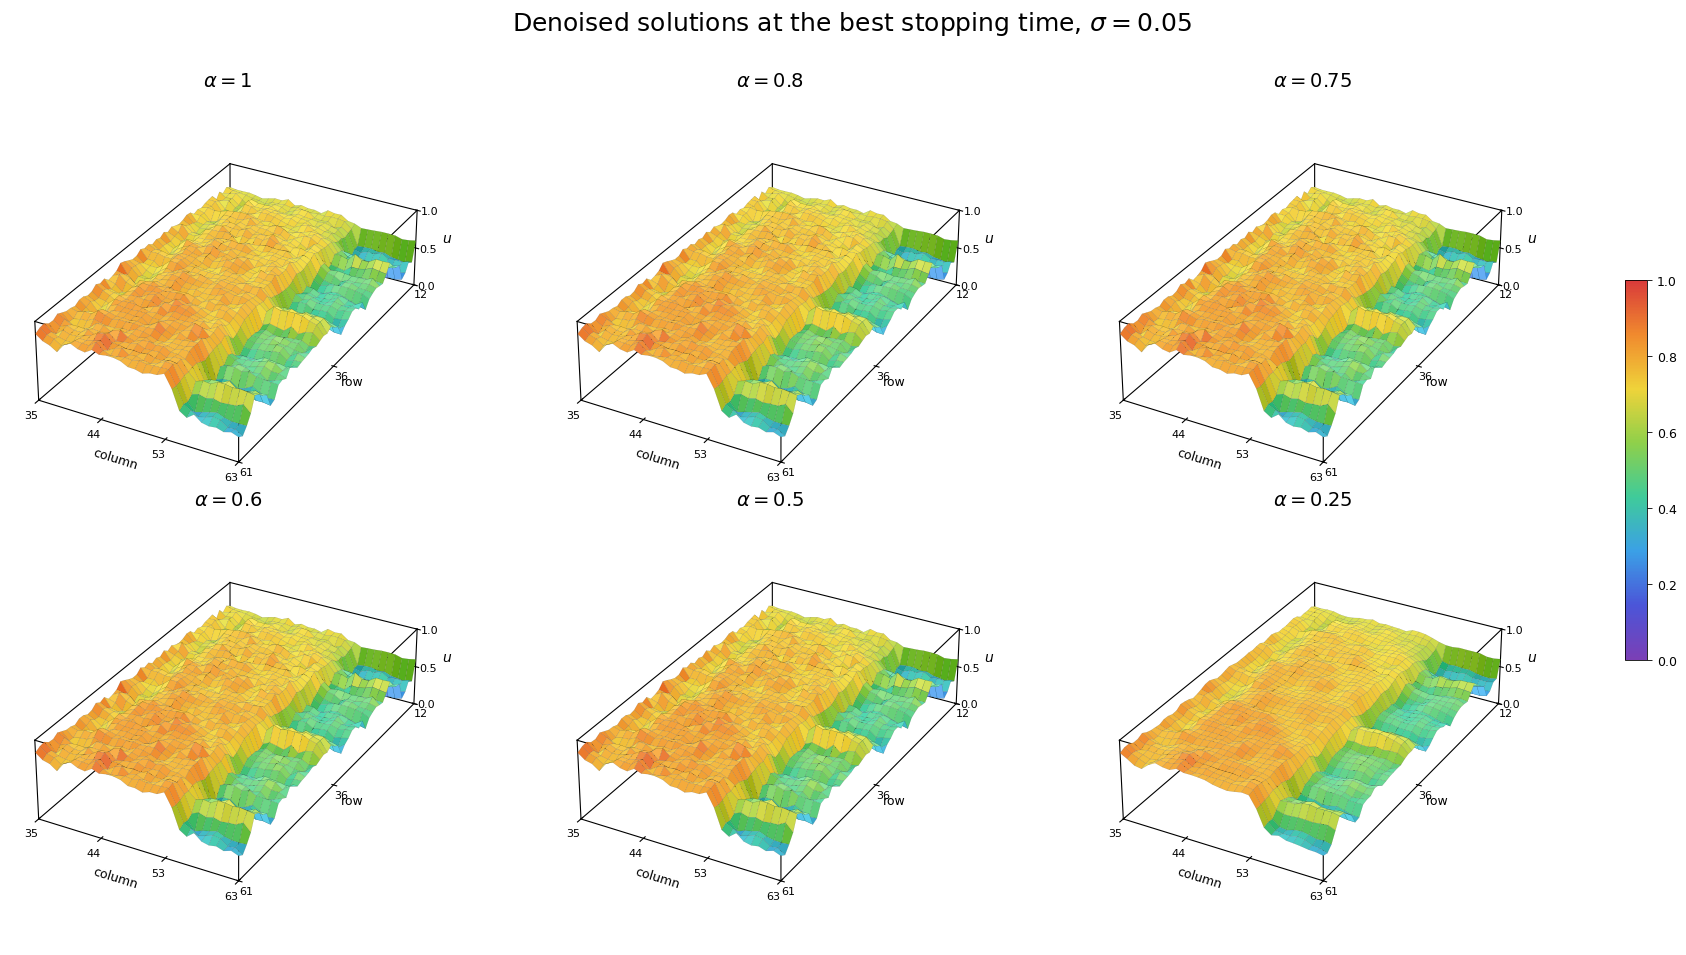

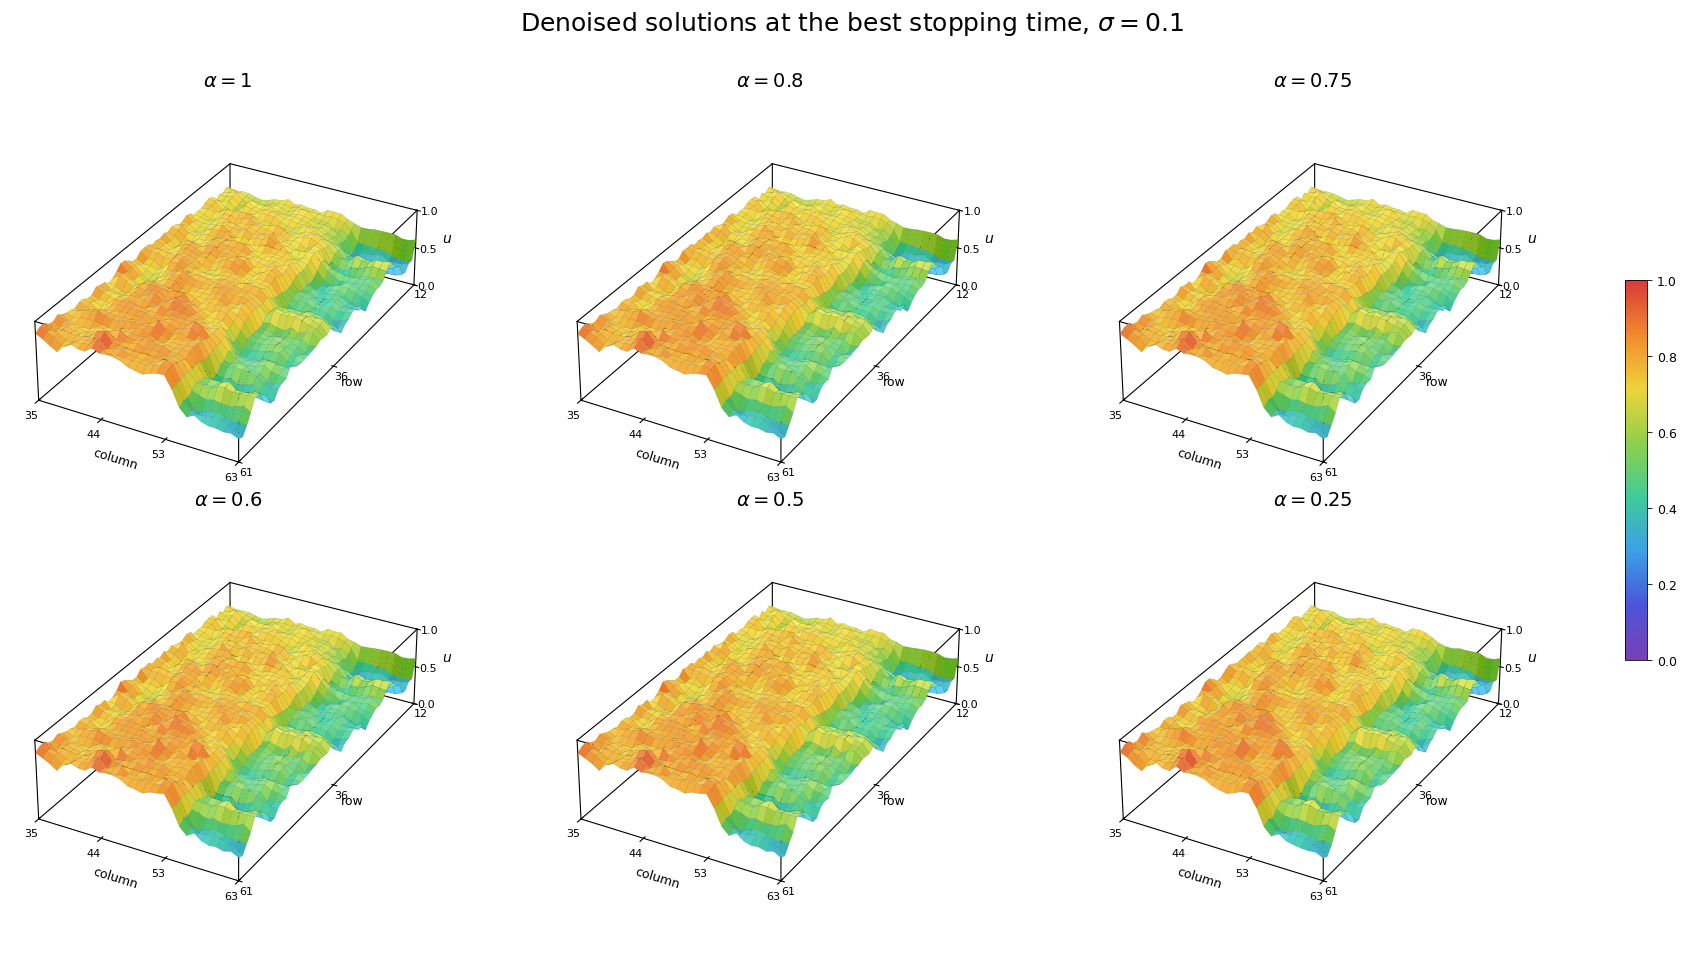

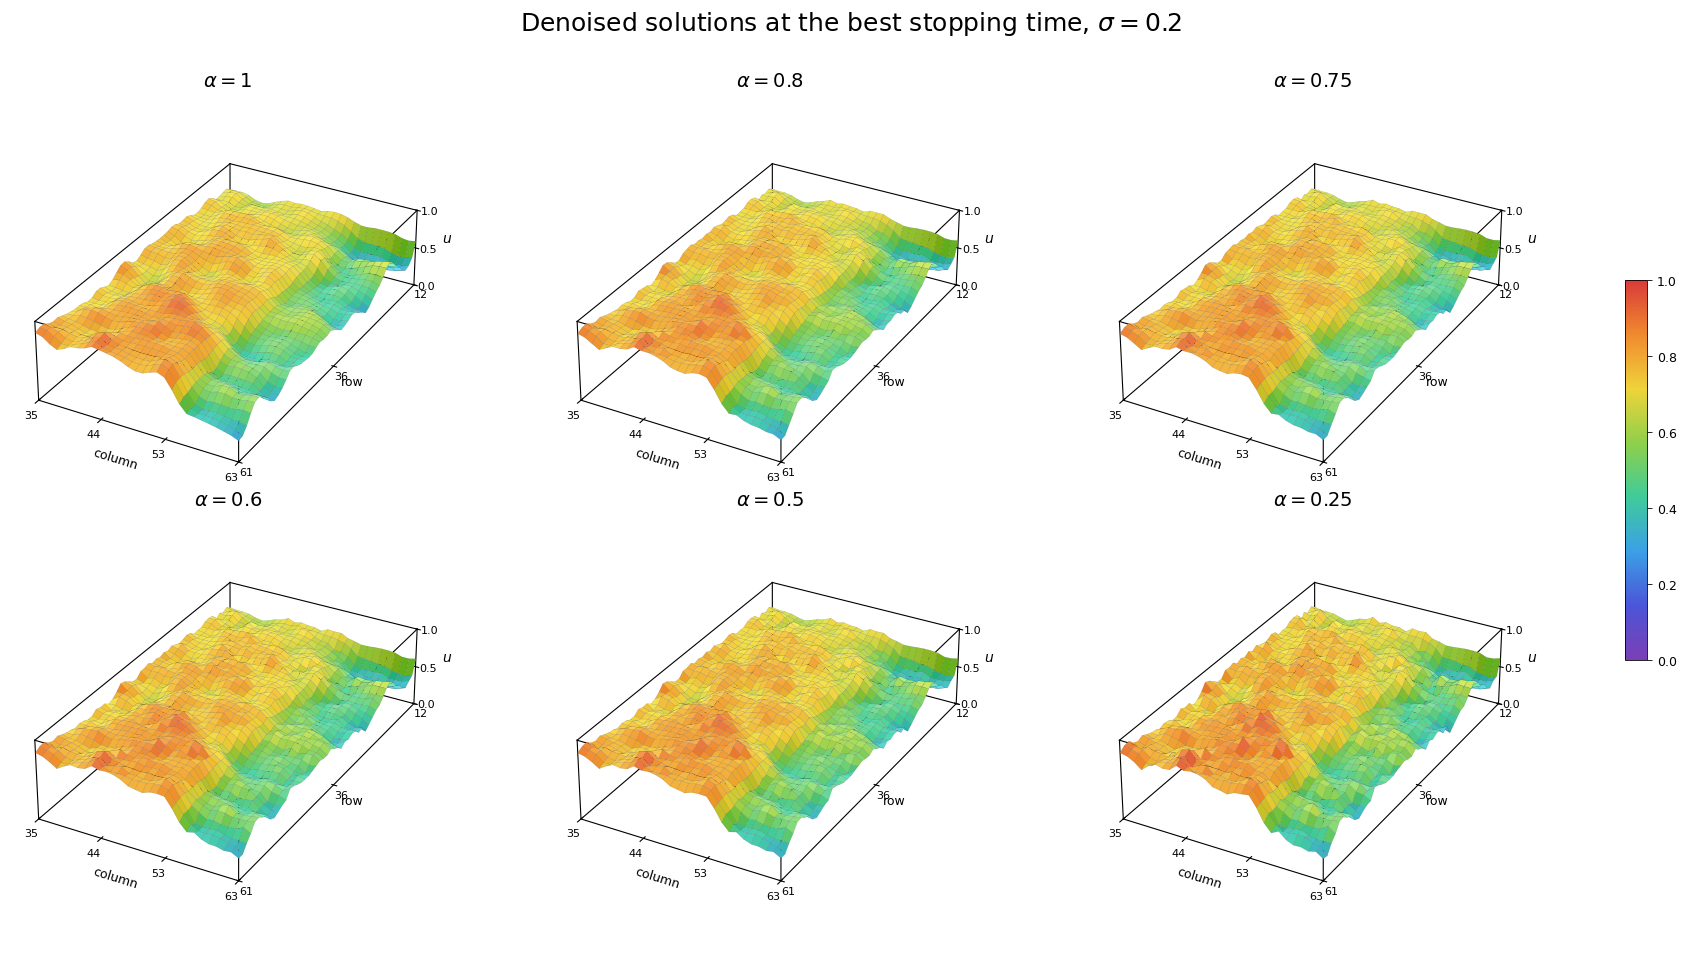

In [134]:
sigmas_3d = [0.05, 0.1, 0.2]

STEP = 1
SHARED_SCALE = True

mma_rainbow = LinearSegmentedColormap.from_list("mma_rainbow", [
    "#7B3FB5", "#4B55D8", "#3BA0E6", "#3FCB9A",
    "#8FD04A", "#EFD33A", "#F08A2E", "#D93A3A"
])

light = LightSource(azdeg=315, altdeg=45)

def draw_box(ax, xlim, ylim, zlim):
    x0, x1 = xlim
    y0, y1 = ylim
    z0, z1 = zlim

    for y in (y0, y1):
        for z in (z0, z1):
            ax.plot([x0, x1], [y, y], [z, z], color="black", lw=0.8)

    for x in (x0, x1):
        for z in (z0, z1):
            ax.plot([x, x], [y0, y1], [z, z], color="black", lw=0.8)

    for x in (x0, x1):
        for y in (y0, y1):
            ax.plot([x, x], [y, y], [z0, z1], color="black", lw=0.8)


for sigma in sigmas_3d:
    fig = plt.figure(figsize=(18, 9.5))

    for k, alpha in enumerate(alphas, 1):
        ax = fig.add_subplot(2, 3, k, projection="3d")

        u_full = comparison[sigma][alpha]["best_img"]

        r0, r1 = min(12, u_full.shape[0] - 1), min(62, u_full.shape[0])
        c0, c1 = min(35, u_full.shape[1] - 1), min(85, u_full.shape[1])

        u = u_full[r0:r1:STEP, c0:c1:STEP]
        rows = np.arange(r0, r1, STEP)
        cols = np.arange(c0, c1, STEP)
        X, Y = np.meshgrid(cols, rows)

        lo, hi = (0, 1) if SHARED_SCALE else (u.min(), u.max())
        norm = Normalize(lo, hi)

        colours = light.shade(
            u, cmap=mma_rainbow, norm=norm,
            blend_mode="soft", vert_exag=1.2,
            dx=STEP, dy=STEP
        )

        ax.plot_surface(
            X, Y, u,
            facecolors=colours,
            shade=False,
            edgecolor=(0, 0, 0, 0.28),
            linewidth=0.2
        )

        xl = (cols[0], cols[-1])
        yl = (rows[0], rows[-1])
        zl = (lo, hi)

        ax.set(xlim=xl, ylim=(yl[1], yl[0]), zlim=zl)
        draw_box(ax, xl, yl, zl)
        ax.set_box_aspect((len(cols), len(rows), 0.4 * len(cols)))
        ax.view_init(elev=30, azim=-61)
        ax.grid(False)

        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.set_pane_color((1, 1, 1, 0))
            axis.line.set_color((0, 0, 0, 0))

        ax.set_xticks(np.linspace(*xl, min(4, len(cols))).astype(int))
        ax.set_yticks(np.linspace(*yl, min(3, len(rows))).astype(int))
        ax.set_zticks(np.linspace(lo, hi, 3))
        ax.tick_params(labelsize=8, pad=-2)
        ax.set_xlabel("column", fontsize=9, labelpad=-4)
        ax.set_ylabel("row", fontsize=9, labelpad=-4)
        ax.set_zlabel(r"$u$", fontsize=10, labelpad=-6)
        ax.set_title(rf"$\alpha={alpha}$", fontsize=14, pad=-14)

    cax = fig.add_axes([0.93, 0.30, 0.012, 0.40])
    cbar = fig.colorbar(
        ScalarMappable(norm=Normalize(0, 1), cmap=mma_rainbow),
        cax=cax,
        ticks=np.linspace(0, 1, 6)
    )
    cbar.outline.set_linewidth(0.6)
    cbar.ax.tick_params(labelsize=9, width=0.6)

    fig.suptitle(
        rf"Denoised solutions at the best stopping time, $\sigma={sigma}$",
        fontsize=18, y=0.985
    )
    fig.subplots_adjust(
        left=0, right=0.91, bottom=0, top=0.90,
        wspace=-0.02, hspace=-0.04
    )

    plt.savefig(
        f"denoised_solutions_sigma{sigma}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()

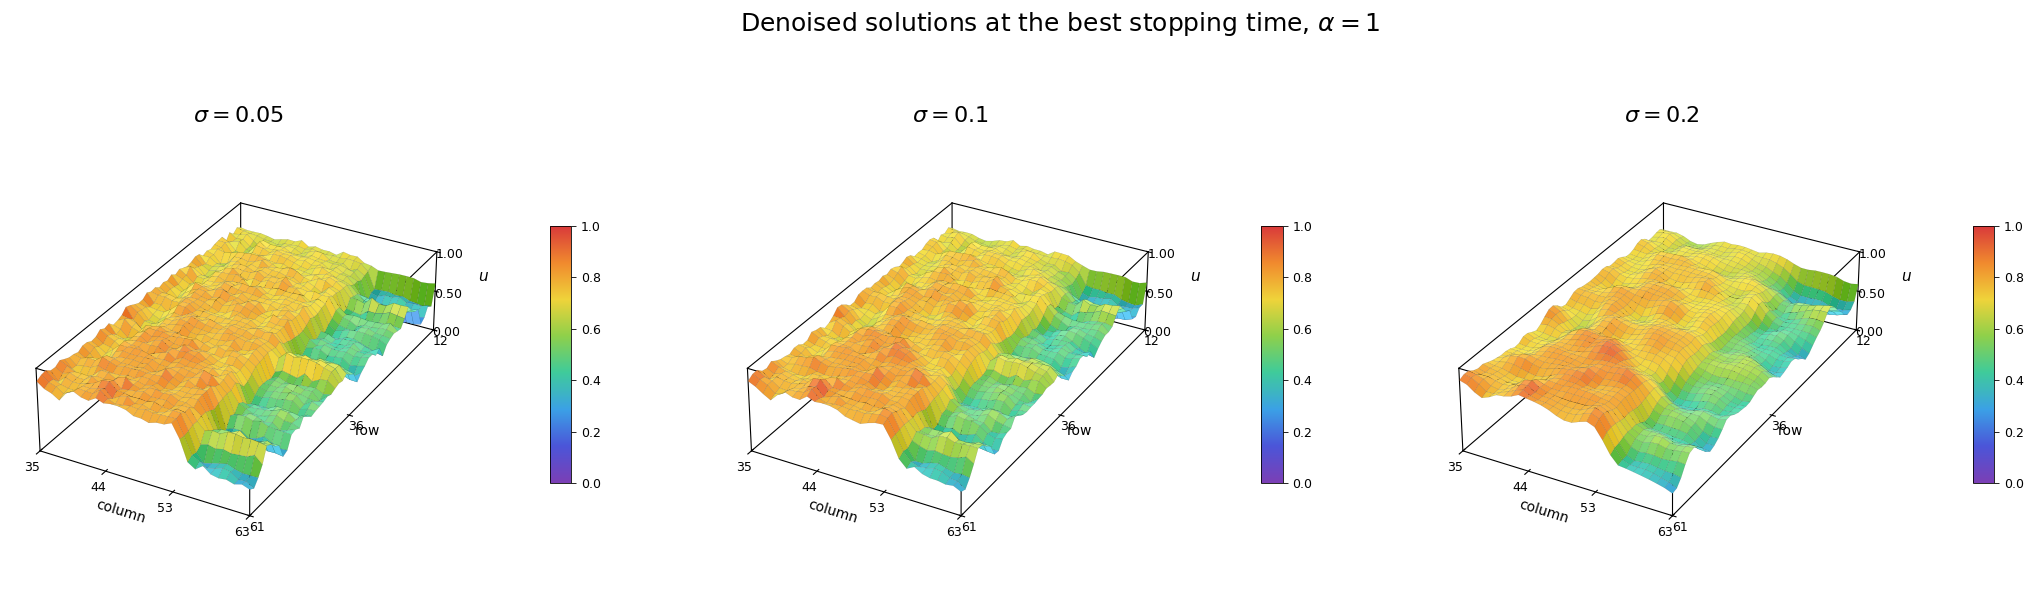

In [135]:
alpha = 1
OWN_SCALE = False

fig = plt.figure(figsize=(21, 6.5), facecolor="white")

for k, sigma in enumerate(sigmas_3d, 1):
    ax = fig.add_subplot(1, len(sigmas_3d), k, projection="3d")

    u_full = comparison[sigma][alpha]["best_img"]

    r0, r1 = min(12, u_full.shape[0] - 1), min(62, u_full.shape[0])
    c0, c1 = min(35, u_full.shape[1] - 1), min(85, u_full.shape[1])

    u = u_full[r0:r1, c0:c1]
    rows = np.arange(r0, r1)
    cols = np.arange(c0, c1)
    X1, Y1 = np.meshgrid(cols, rows)

    lo, hi = (u.min(), u.max()) if OWN_SCALE else (0, 1)
    norm = Normalize(lo, hi)

    colours = light.shade(
        u, cmap=mma_rainbow, norm=norm,
        blend_mode="soft", vert_exag=1.2 * (hi - lo)
    )

    ax.plot_surface(
        X1, Y1, u, facecolors=colours, shade=False,
        edgecolor=(0, 0, 0, 0.28), linewidth=0.2,
        antialiased=True
    )

    xl, yl, zl = (cols[0], cols[-1]), (rows[0], rows[-1]), (lo, hi)
    ax.set(xlim=xl, ylim=(yl[1], yl[0]), zlim=zl)
    draw_box(ax, xl, yl, zl)

    ax.set_box_aspect((len(cols), len(rows), 0.4 * len(cols)))
    ax.view_init(elev=30, azim=-61)
    ax.grid(False)

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1, 1, 1, 0))
        axis.line.set_color((0, 0, 0, 0))

    ax.set_xticks(np.linspace(*xl, min(4, len(cols))).astype(int))
    ax.set_yticks(np.linspace(*yl, min(3, len(rows))).astype(int))
    ax.set_zticks(np.linspace(lo, hi, 3))
    ax.zaxis.set_major_formatter("{x:.2f}")
    ax.tick_params(labelsize=9, pad=-2)
    ax.set_xlabel("column", fontsize=10, labelpad=-4)
    ax.set_ylabel("row", fontsize=10, labelpad=-4)
    ax.set_zlabel(r"$u$", fontsize=11, labelpad=2)
    ax.set_title(rf"$\sigma={sigma}$", fontsize=16, pad=-14)

    cbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=mma_rainbow),
        ax=ax, shrink=0.45, aspect=12, pad=0.13
    )
    cbar.outline.set_linewidth(0.6)
    cbar.ax.tick_params(labelsize=9, width=0.6)

fig.suptitle(
    r"Denoised solutions at the best stopping time, $\alpha=1$",
    fontsize=18, y=0.97
)
fig.subplots_adjust(
    left=0, right=0.98, bottom=0, top=0.88, wspace=0.12
)

plt.savefig(
    "denoised_solutions_alpha1.png",
    dpi=200, bbox_inches="tight", facecolor="white"
)
plt.show()

In [136]:
import shutil
from google.colab import files

shutil.make_archive("crankplots", "zip", "crankplots")
files.download("crankplots.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>